<a href="https://colab.research.google.com/github/Xyrfo/Pembelajaran-Mesin/blob/main/JS08/TugasLab1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tugas Lab 1
Gunakan dataset CC_Customer_Dataset.csv dari Tugas Lab



*   Buatlah model klasterisasi
dengan menggunakan Agglomerative Clustering dengan seluruh variabel yang dapat digunakan.





In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage

In [14]:
uploaded = files.upload()
nama_file = next(iter(uploaded))
df = pd.read_csv(nama_file)
print('Ukuran data:', df.shape)
df.head()

Saving CC_Customer_Dataset.csv to CC_Customer_Dataset (1).csv
Ukuran data: (660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


Variabel yang dipakai: ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']


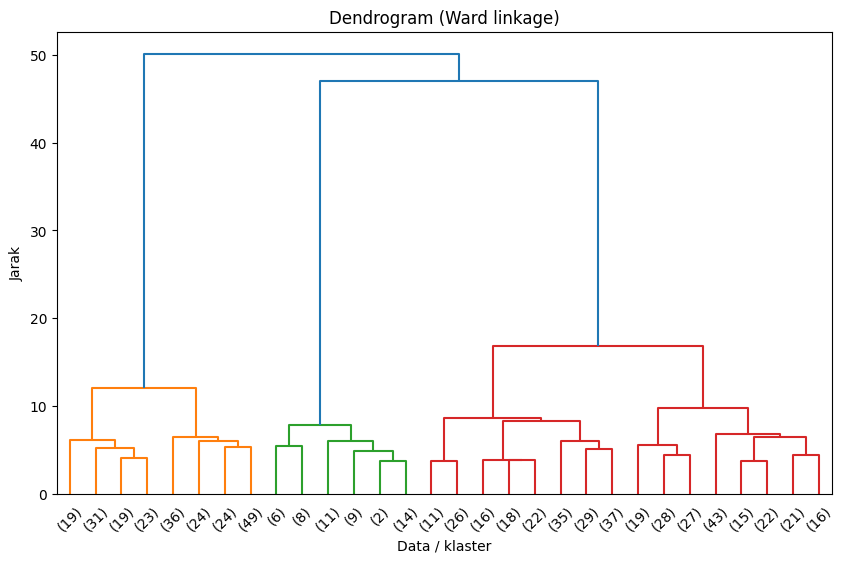

k=2 | Silhouette=0.4177 | Davies-Bouldin=0.9326
k=3 | Silhouette=0.5148 | Davies-Bouldin=0.6810
k=4 | Silhouette=0.3481 | Davies-Bouldin=1.1493
k=5 | Silhouette=0.2569 | Davies-Bouldin=1.3851
k=6 | Silhouette=0.2268 | Davies-Bouldin=1.4109
k=7 | Silhouette=0.2163 | Davies-Bouldin=1.4394


In [15]:
# 1. Pilih seluruh variabel numerik, buang kolom ID
kolom_id = ['Sl_No', 'Customer Key']   # sesuaikan dengan nama kolom di data Anda
fitur = df.select_dtypes(include=np.number).drop(columns=kolom_id, errors='ignore')
print('Variabel yang dipakai:', list(fitur.columns))

# 2. Standarisasi
scaler = StandardScaler()
X = scaler.fit_transform(fitur)

# 3. Dendrogram
plt.figure(figsize=(10, 6))
dendrogram(linkage(X, method='ward'), truncate_mode='lastp', p=30)
plt.title('Dendrogram (Ward linkage)')
plt.xlabel('Data / klaster')
plt.ylabel('Jarak')
plt.show()

# 4. Cari jumlah klaster terbaik
for k in range(2, 8):
    lbl = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)
    print(f'k={k} | Silhouette={silhouette_score(X, lbl):.4f} | Davies-Bouldin={davies_bouldin_score(X, lbl):.4f}')

Cluster
0    385
1    225
2     50
Name: count, dtype: int64
         Avg_Credit_Limit  Total_Credit_Cards  Total_visits_bank  \
Cluster                                                            
0                33851.95                5.52               3.49   
1                12151.11                2.42               0.94   
2               141040.00                8.74               0.60   

         Total_visits_online  Total_calls_made  
Cluster                                         
0                       0.98              1.99  
1                       3.55              6.86  
2                      10.90              1.08  


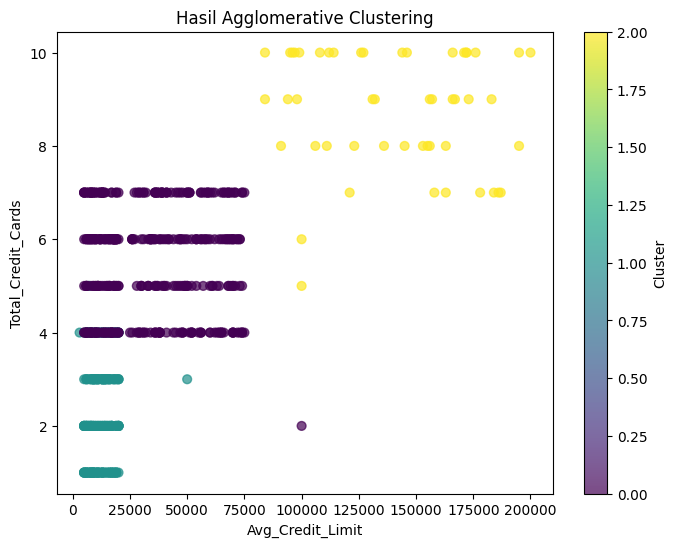

In [16]:
# 5. Model final (ganti k sesuai hasil terbaik)
k_terbaik = 3
model = AgglomerativeClustering(n_clusters=k_terbaik, linkage='ward')
df['Cluster'] = model.fit_predict(X)

print(df['Cluster'].value_counts().sort_index())

# 6. Profil tiap klaster
profil = df.groupby('Cluster')[list(fitur.columns)].mean().round(2)
print(profil)

# 7. Visualisasi
plt.figure(figsize=(8, 6))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'], c=df['Cluster'], cmap='viridis', s=40, alpha=0.7)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Hasil Agglomerative Clustering')
plt.colorbar(label='Cluster')
plt.show()

*   Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu Avg_Credit_Limit dan Total_credit_card. Tunjukkan bentuk cluster-nya berdasarkan dua fitur tersebut.


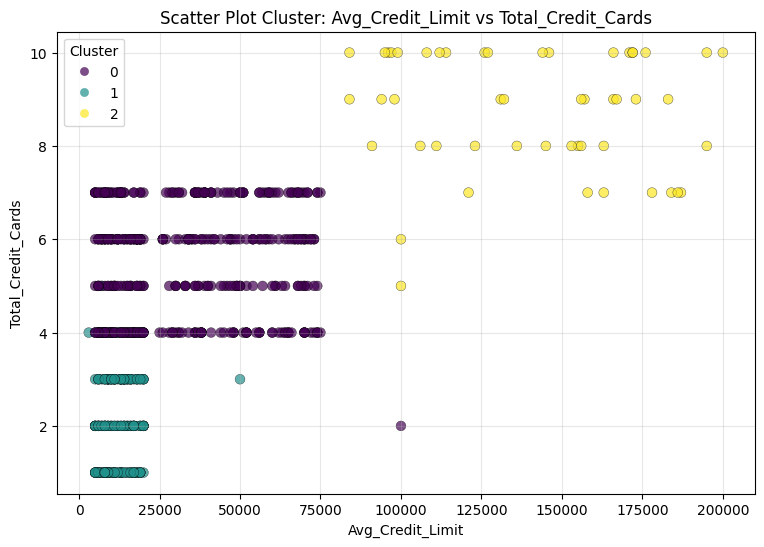

In [17]:
plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    df['Avg_Credit_Limit'],
    df['Total_Credit_Cards'],
    c=df['Cluster'],
    cmap='viridis',
    s=50,
    alpha=0.7,
    edgecolors='k',
    linewidths=0.3
)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Scatter Plot Cluster: Avg_Credit_Limit vs Total_Credit_Cards')
plt.legend(*scatter.legend_elements(), title='Cluster')
plt.grid(alpha=0.3)
plt.show()

*  Tentukan nilai silhouette score dan DBI dari model.

In [18]:
sil = silhouette_score(X, df['Cluster'])
dbi = davies_bouldin_score(X, df['Cluster'])

print(f'Jumlah cluster      : {k_terbaik}')
print(f'Silhouette Score    : {sil:.4f}')
print(f'Davies-Bouldin Index: {dbi:.4f}')

Jumlah cluster      : 3
Silhouette Score    : 0.5148
Davies-Bouldin Index: 0.6810


In [19]:
X_2fitur = StandardScaler().fit_transform(df[['Avg_Credit_Limit', 'Total_Credit_Cards']])
print(f'Silhouette (2 fitur): {silhouette_score(X_2fitur, df["Cluster"]):.4f}')
print(f'DBI (2 fitur)       : {davies_bouldin_score(X_2fitur, df["Cluster"]):.4f}')

Silhouette (2 fitur): 0.4371
DBI (2 fitur)       : 0.7075
